# Assignment 3: Time-Series Forecasting — Expanded Experiments

Forecast air temperature **24 hours ahead** using the preceding **five days of hourly weather observations** from the Jena Climate dataset.


## 1. Imports and experiment settings

A consistent data split, forecasting task, optimizer, and training budget are used across models. Fixed seeds make comparisons more reproducible, although GPU operations can still introduce small variation.

In [1]:
import os
import re
import glob
import random
import base64
import shutil
import zipfile
from pathlib import Path
from html import escape

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from matplotlib.backends.backend_pdf import PdfPages
from IPython.display import display

SEED = 42
HISTORY = 120               # Five days of hourly weather readings
HORIZON = 24                # Temperature 24 hours after the last input
STRIDE = 6                  # One new forecast example every six hours
MAX_EPOCHS = 15
PATIENCE = 3
BATCH_SIZE = 256
LEARNING_RATE = 0.001
AUTHOR = 'Aamir Sohaib'

OUT = Path('/kaggle/working/Assignment_3_Expanded')
OUT.mkdir(parents=True, exist_ok=True)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print('TensorFlow:', tf.__version__)
print('Available GPUs:', tf.config.list_physical_devices('GPU'))
print('Results directory:', OUT)

TensorFlow: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Results directory: /kaggle/working/Assignment_3_Expanded


## 2. Load, clean, and chronologically split the weather data

Convert the original ten-minute observations to hourly averages, replace invalid missing-value markers, and carry forward earlier observations when a value is missing. Fit standardization statistics on **training data only**.

In [2]:
paths = sorted(set(glob.glob('/kaggle/input/**/jena_climate_2009_2016.csv', recursive=True)))
if len(paths) != 1:
    raise FileNotFoundError(
        'Expected one Jena CSV under /kaggle/input; found ' + str(paths) +
        '. In Kaggle, use Add Input > Datasets and attach Jena Climate 2009-2016.'
    )

df = pd.read_csv(paths[0])
df['Date Time'] = pd.to_datetime(df['Date Time'], format='%d.%m.%Y %H:%M:%S')
df = df.sort_values('Date Time')
target_col = 'T (degC)'
features = [col for col in df.columns if col != 'Date Time']
assert target_col in features, 'Expected temperature target column was not found.'

missing_markers = int((df[features] == -9999).sum().sum())
raw = df.set_index('Date Time')[features].replace(-9999, np.nan)
hourly_raw = raw.resample('1h').mean()
missing_hours = int(hourly_raw[target_col].isna().sum())
hourly = hourly_raw.ffill().reset_index()

assert not hourly[features].isna().any().any(), 'Missing values remain after forward filling.'
assert hourly['Date Time'].diff().dropna().eq(pd.Timedelta(hours=1)).all()

n = len(hourly)
cut1, cut2 = int(0.70 * n), int(0.85 * n)
segments = {
    'train': hourly.iloc[:cut1].copy(),
    'validation': hourly.iloc[cut1:cut2].copy(),
    'test': hourly.iloc[cut2:].copy()
}
mu = segments['train'][features].mean().to_numpy(dtype='float32')
sigma = segments['train'][features].std().replace(0, 1).to_numpy(dtype='float32')
temp_idx = features.index(target_col)
assert (sigma > 0).all()

split_summary = pd.DataFrame([
    {'Split': k, 'Hours': len(v),
     'Start': str(v['Date Time'].iloc[0]), 'End': str(v['Date Time'].iloc[-1])}
    for k, v in segments.items()
])
print(f'Original readings: {len(df):,} | Hourly readings: {n:,} | Features: {len(features)}')
print('Missing markers:', missing_markers, '| Hours with missing temperature:', missing_hours)
display(split_summary)

Original readings: 420,551 | Hourly readings: 70,129 | Features: 14
Missing markers: 38 | Hours with missing temperature: 88


,Split,Hours,Start,End
0,train,49090,2009-01-01 00:00:00,2014-08-08 09:00:00
1,validation,10519,2014-08-08 10:00:00,2015-10-20 16:00:00
2,test,10520,2015-10-20 17:00:00,2017-01-01 00:00:00


## 3. Make identical forecast windows for every model

Each input has shape `(120 hours, 14 weather features)`. The target is the temperature **24 hours later**. All inputs and targets stay strictly inside their own chronological split.

In [3]:
def make_windows(part):
    values = part[features].to_numpy(dtype='float32')
    scaled = (values - mu) / sigma
    starts = np.arange(0, len(part) - HISTORY - HORIZON + 1, STRIDE)
    if len(starts) == 0:
        raise ValueError('The split is too short for the chosen input/history settings.')
    last_input_idx = starts + HISTORY - 1
    target_idx = last_input_idx + HORIZON
    X = np.stack([scaled[s:s + HISTORY] for s in starts]).astype('float32')
    y = scaled[target_idx, temp_idx].astype('float32')
    actual = values[target_idx, temp_idx]
    persistence = values[last_input_idx, temp_idx]
    target_dates = part['Date Time'].iloc[target_idx].reset_index(drop=True)
    last_input_dates = part['Date Time'].iloc[last_input_idx].reset_index(drop=True)
    assert (target_dates - last_input_dates).eq(pd.Timedelta(hours=HORIZON)).all()
    assert X.shape[1:] == (HISTORY, len(features))
    return X, y, actual, persistence, target_dates

X_train, y_train, _, _, _ = make_windows(segments['train'])
X_val, y_val, val_actual, val_baseline, val_dates = make_windows(segments['validation'])
baseline_val_mae = float(np.mean(np.abs(val_actual - val_baseline)))
assert np.isfinite(baseline_val_mae)

print('Training windows:', X_train.shape, '| Validation windows:', X_val.shape)
print('Validation baseline MAE: {:.3f} °C'.format(baseline_val_mae))

Training windows: (8158, 120, 14) | Validation windows: (1730, 120, 14)
Validation baseline MAE: 2.586 °C


## 4. Models: single-layer, Conv1D + GRU, and stacked recurrent layers

The first layer of each stacked model sets `return_sequences=True`, allowing the next recurrent layer to process the full time sequence. **Both 32→64 and 64→32** unit arrangements are tested for GRU and LSTM.

In [4]:
# Nine neural models plus one common-sense baseline.
SPECS = [
    ('GRU 32', 'GRU', (32,)),
    ('GRU 64', 'GRU', (64,)),
    ('LSTM 32', 'LSTM', (32,)),
    ('LSTM 64', 'LSTM', (64,)),
    ('Conv1D + GRU 32', 'ConvGRU', (32,)),
    ('Stacked GRU 32-64', 'GRU', (32, 64)),
    ('Stacked GRU 64-32', 'GRU', (64, 32)),
    ('Stacked LSTM 32-64', 'LSTM', (32, 64)),
    ('Stacked LSTM 64-32', 'LSTM', (64, 32)),
]

def build_model(kind, units):
    inputs = tf.keras.Input(shape=(HISTORY, len(features)))
    x = inputs
    if kind == 'ConvGRU':
        x = tf.keras.layers.Conv1D(32, 5, padding='causal', activation='relu')(x)
        x = tf.keras.layers.GRU(units[0])(x)
    elif kind in ('GRU', 'LSTM'):
        layer_type = tf.keras.layers.GRU if kind == 'GRU' else tf.keras.layers.LSTM
        for i, number_of_units in enumerate(units):
            x = layer_type(number_of_units, return_sequences=(i < len(units) - 1))(x)
    else:
        raise ValueError('Unknown model family: ' + kind)
    output = tf.keras.layers.Dense(1)(x)
    model = tf.keras.Model(inputs=inputs, outputs=output)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE), loss='mae')
    return model

model_design = pd.DataFrame([
    {'Model': name, 'Architecture': kind, 'Recurrent units': ' → '.join(map(str, units)),
     'Stacked recurrent layers': len(units) if kind in ('GRU', 'LSTM') else 1}
    for name, kind, units in SPECS
])
display(model_design)
assert len(SPECS) == 9 and len({name for name, _, _ in SPECS}) == 9

,Model,Architecture,Recurrent units,Stacked recurrent layers
0,GRU 32,GRU,32,1
1,GRU 64,GRU,64,1
2,LSTM 32,LSTM,32,1
3,LSTM 64,LSTM,64,1
4,Conv1D + GRU 32,ConvGRU,32,1
5,Stacked GRU 32-64,GRU,32 → 64,2
6,Stacked GRU 64-32,GRU,64 → 32,2
7,Stacked LSTM 32-64,LSTM,32 → 64,2
8,Stacked LSTM 64-32,LSTM,64 → 32,2


## 5. Train all neural models and record validation MAE

The same input, target, optimizer, loss, training budget, and model-selection metric apply to each configuration. Early stopping restores the best validation weights. This cell trains all nine neural models from scratch, so do not interrupt it midway.

In [5]:
tf.keras.backend.clear_session()
models, histories = {}, {}
validation_rows = [{
    'Model': 'Seasonal persistence', 'Family': 'Baseline', 'Units': '—',
    'Epochs': 0, 'Parameters': 0, 'Validation MAE (°C)': baseline_val_mae
}]

for i, (name, kind, units) in enumerate(SPECS):
    tf.keras.utils.set_random_seed(SEED + i)
    model = build_model(kind, units)
    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=PATIENCE, min_delta=1e-4, restore_best_weights=True
        ),
        tf.keras.callbacks.TerminateOnNaN()
    ]
    print('\n=== Training', name, '===', flush=True)
    history = model.fit(
        X_train, y_train, validation_data=(X_val, y_val),
        epochs=MAX_EPOCHS, batch_size=BATCH_SIZE,
        callbacks=callbacks, verbose=2, shuffle=True
    )
    predictions = model.predict(X_val, batch_size=512, verbose=0).ravel()
    predictions_c = predictions * sigma[temp_idx] + mu[temp_idx]
    val_mae = float(np.mean(np.abs(val_actual - predictions_c)))
    assert np.isfinite(val_mae), name + ': non-finite validation MAE'
    models[name] = model
    histories[name] = history.history
    validation_rows.append({
        'Model': name, 'Family': kind, 'Units': ' → '.join(map(str, units)),
        'Epochs': len(history.history['loss']), 'Parameters': model.count_params(),
        'Validation MAE (°C)': val_mae
    })
    print('{}: validation MAE = {:.3f} °C'.format(name, val_mae), flush=True)

validation_table = pd.DataFrame(validation_rows).sort_values('Validation MAE (°C)').reset_index(drop=True)
best_name = validation_table.iloc[0]['Model']
runner_up = validation_table.iloc[1]['Model']
print('\nSelected using VALIDATION ONLY:', best_name)
display(validation_table.round(3))
validation_table.to_csv(OUT / 'validation_results_all_models.csv', index=False)


=== Training GRU 32 ===
Epoch 1/15
32/32 - 3s - 82ms/step - loss: 0.4164 - val_loss: 0.2957
Epoch 2/15
32/32 - 0s - 12ms/step - loss: 0.3091 - val_loss: 0.2902
Epoch 3/15
32/32 - 0s - 11ms/step - loss: 0.2974 - val_loss: 0.2875
Epoch 4/15
32/32 - 0s - 11ms/step - loss: 0.2926 - val_loss: 0.2853
Epoch 5/15
32/32 - 0s - 11ms/step - loss: 0.2894 - val_loss: 0.2839
Epoch 6/15
32/32 - 0s - 11ms/step - loss: 0.2870 - val_loss: 0.2825
Epoch 7/15
32/32 - 0s - 11ms/step - loss: 0.2851 - val_loss: 0.2815
Epoch 8/15
32/32 - 0s - 11ms/step - loss: 0.2835 - val_loss: 0.2803
Epoch 9/15
32/32 - 0s - 11ms/step - loss: 0.2822 - val_loss: 0.2794
Epoch 10/15
32/32 - 0s - 11ms/step - loss: 0.2810 - val_loss: 0.2785
Epoch 11/15
32/32 - 0s - 11ms/step - loss: 0.2798 - val_loss: 0.2777
Epoch 12/15
32/32 - 0s - 11ms/step - loss: 0.2784 - val_loss: 0.2769
Epoch 13/15
32/32 - 0s - 11ms/step - loss: 0.2775 - val_loss: 0.2764
Epoch 14/15
32/32 - 0s - 11ms/step - loss: 0.2766 - val_loss: 0.2756
Epoch 15/15
32/32 

,Model,Family,Units,Epochs,Parameters,Validation MAE (°C)
0,GRU 32,GRU,32,15,4641,2.380
1,Stacked GRU 64-32,GRU,64 → 32,15,24801,2.401
2,LSTM 64,LSTM,64,12,20289,2.409
3,Stacked LSTM 64-32,LSTM,64 → 32,15,32673,2.411
4,Stacked GRU 32-64,GRU,32 → 64,15,23489,2.417
5,Conv1D + GRU 32,ConvGRU,32,15,8641,2.431
6,Stacked LSTM 32-64,LSTM,32 → 64,13,30913,2.450
7,LSTM 32,LSTM,32,15,6049,2.467
8,GRU 64,GRU,64,9,15425,2.469
9,Seasonal persistence,Baseline,—,0,0,2.586


## 6. Evaluate **all ten approaches** on the untouched test period

Model selection is already frozen using validation results. All test scores below are for transparent reporting and comparison **only**—they are not used to reselect the winner or tune hyperparameters.

In [6]:
X_test, y_test, test_actual, test_baseline, test_dates = make_windows(segments['test'])
all_test_predictions = {'Seasonal persistence': test_baseline}

# All nine trained neural models are evaluated against the same test windows.
for name, _, _ in SPECS:
    scaled_predictions = models[name].predict(X_test, batch_size=512, verbose=0).ravel()
    all_test_predictions[name] = scaled_predictions * sigma[temp_idx] + mu[temp_idx]

mae_test = {
    name: float(np.mean(np.abs(test_actual - predicted)))
    for name, predicted in all_test_predictions.items()
}
assert all(np.isfinite(value) for value in mae_test.values())
assert len(mae_test) == len(SPECS) + 1

full_results = validation_table.copy()
full_results['Test MAE (°C)'] = full_results['Model'].map(mae_test)
full_results['Selected by validation'] = full_results['Model'].eq(best_name)
full_results['Validation rank'] = np.arange(1, len(full_results) + 1)
full_results['Change vs baseline (validation %)'] = (
    100 * (baseline_val_mae - full_results['Validation MAE (°C)']) / baseline_val_mae
)
full_results['Change vs baseline (test %)'] = (
    100 * (mae_test['Seasonal persistence'] - full_results['Test MAE (°C)'])
    / mae_test['Seasonal persistence']
)
assert full_results['Test MAE (°C)'].notna().all()
assert bool(full_results.iloc[0]['Selected by validation'])
full_results.to_csv(OUT / 'all_model_validation_and_test_MAE.csv', index=False)

def safe_label(name):
    return re.sub(r'[^a-z0-9]+', '_', name.lower()).strip('_')

prediction_table = pd.DataFrame({
    'target_time': test_dates,
    'actual_temperature_C': test_actual,
})
for name, predicted in all_test_predictions.items():
    prediction_table['predicted_' + safe_label(name) + '_C'] = predicted
prediction_table.to_csv(OUT / 'test_predictions_ALL_models.csv', index=False)

print('\nVALIDATION-SELECTED WINNER:', best_name)
print('Validation MAE: {:.3f} °C | Test MAE: {:.3f} °C'.format(
    float(full_results.iloc[0]['Validation MAE (°C)']), mae_test[best_name]
))
print('Test examples:', len(test_actual))
print('Runner-up on validation:', runner_up)
display(full_results[['Validation rank', 'Model', 'Units', 'Epochs',
                      'Validation MAE (°C)', 'Test MAE (°C)',
                      'Selected by validation']].round(3))

# Save the preselected model, but do not use test scores to choose a different winner.
if best_name in models:
    models[best_name].save(OUT / 'validation_selected_best_model.keras')


VALIDATION-SELECTED WINNER: GRU 32
Validation MAE: 2.380 °C | Test MAE: 2.296 °C
Test examples: 1730
Runner-up on validation: Stacked GRU 64-32


,Validation rank,Model,Units,Epochs,Validation MAE (°C),Test MAE (°C),Selected by validation
0,1,GRU 32,32,15,2.380,2.296,True
1,2,Stacked GRU 64-32,64 → 32,15,2.401,2.296,False
2,3,LSTM 64,64,12,2.409,2.302,False
3,4,Stacked LSTM 64-32,64 → 32,15,2.411,2.361,False
4,5,Stacked GRU 32-64,32 → 64,15,2.417,2.302,False
5,6,Conv1D + GRU 32,32,15,2.431,2.309,False
6,7,Stacked LSTM 32-64,32 → 64,13,2.450,2.413,False
7,8,LSTM 32,32,15,2.467,2.347,False
8,9,GRU 64,64,9,2.469,2.387,False
9,10,Seasonal persistence,—,0,2.586,2.500,False


## 7. Plot the complete comparison and forecasting results

The grouped chart shows both errors for every setup. The learning curves show whether models were still improving. The forecast plot uses only the **validation-selected** winning model.

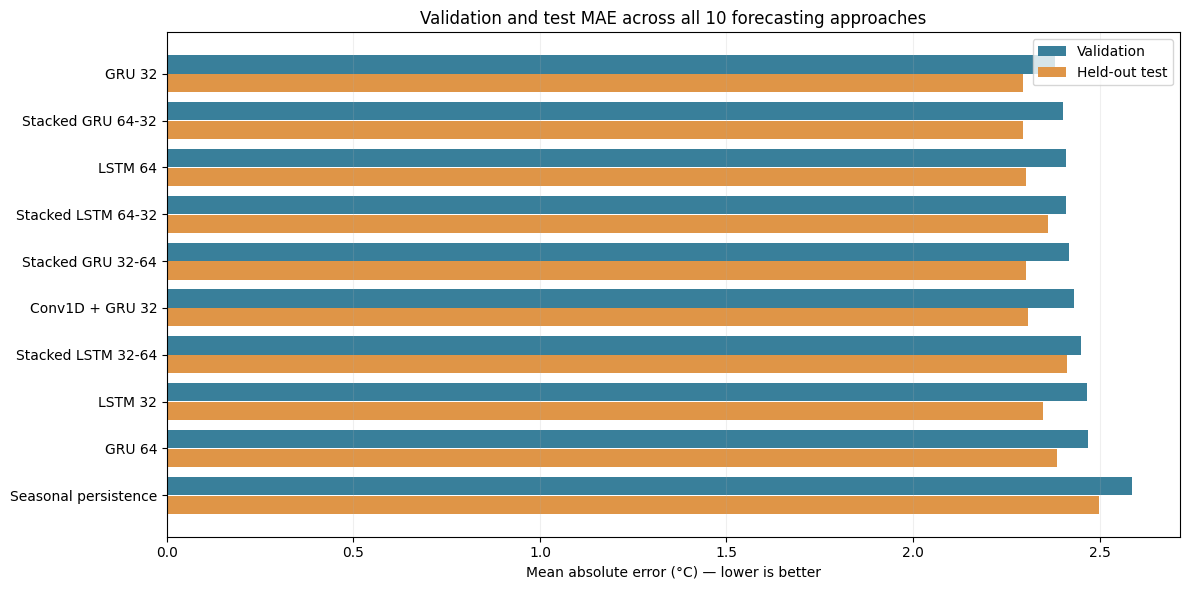

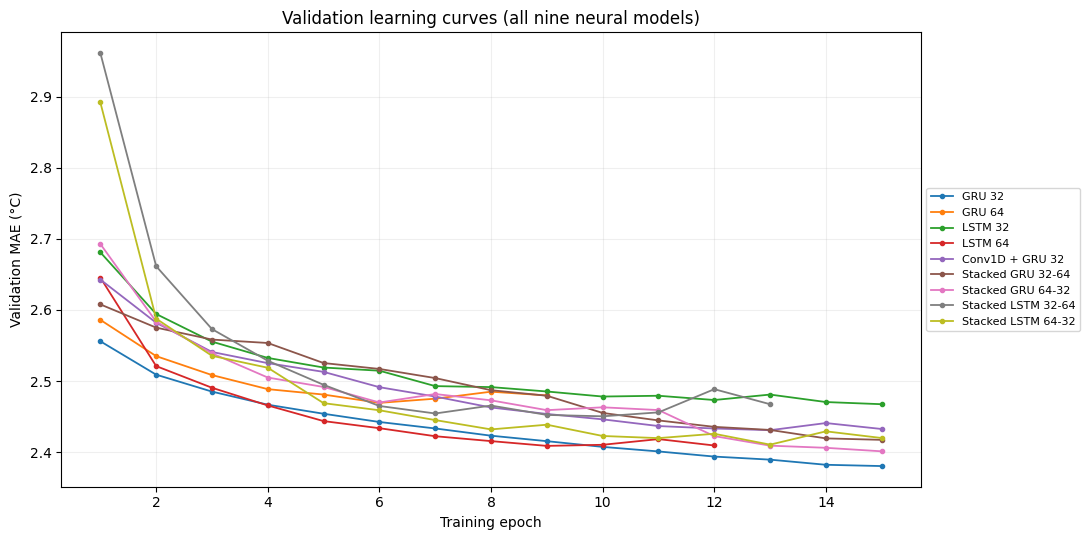

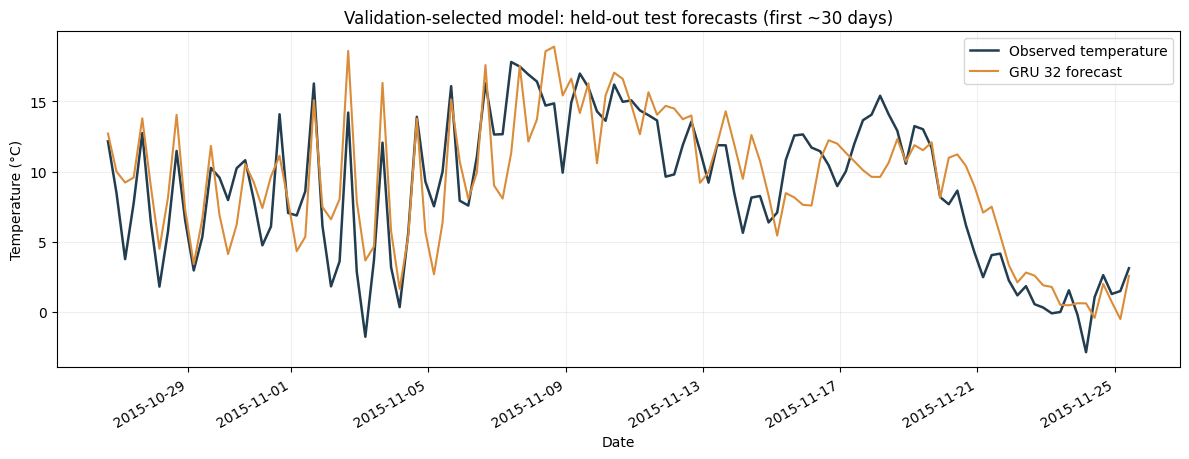

In [7]:
plt.style.use('default')
fig, ax = plt.subplots(figsize=(12, 6))
y_pos = np.arange(len(full_results))
ax.barh(y_pos - 0.2, full_results['Validation MAE (°C)'], height=0.39,
        label='Validation', color='#397f9a')
ax.barh(y_pos + 0.2, full_results['Test MAE (°C)'], height=0.39,
        label='Held-out test', color='#df9547')
ax.set_yticks(y_pos, full_results['Model'])
ax.invert_yaxis()
ax.set(xlabel='Mean absolute error (°C) — lower is better',
       title='Validation and test MAE across all 10 forecasting approaches')
ax.legend()
ax.grid(axis='x', alpha=.2)
fig.tight_layout()
fig.savefig(OUT / 'all_models_validation_vs_test.png', dpi=180, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(11, 5.5))
for name, history in histories.items():
    curve_c = np.asarray(history['val_loss']) * sigma[temp_idx]
    ax.plot(range(1, len(curve_c) + 1), curve_c,
            marker='o', markersize=3, linewidth=1.3, label=name)
ax.set(xlabel='Training epoch', ylabel='Validation MAE (°C)',
       title='Validation learning curves (all nine neural models)')
ax.grid(alpha=.2)
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), fontsize=8)
fig.tight_layout()
fig.savefig(OUT / 'all_models_learning_curves.png', dpi=180, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(12, 4.7))
show = slice(0, 120)  # Every six hours: about 30 days
ax.plot(test_dates.iloc[show], test_actual[show], label='Observed temperature',
        linewidth=1.8, color='#223d50')
ax.plot(test_dates.iloc[show], all_test_predictions[best_name][show],
        label=best_name + ' forecast', linewidth=1.5, color='#da8c39')
ax.set(xlabel='Date', ylabel='Temperature (°C)',
       title='Validation-selected model: held-out test forecasts (first ~30 days)')
ax.grid(alpha=.2)
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(OUT / 'selected_model_test_forecast.png', dpi=180, bbox_inches='tight')
plt.show()

# Keep both loss curves in a CSV so figure values can be audited.
curve_rows = []
for name, history in histories.items():
    for epoch, (train_loss, val_loss) in enumerate(zip(history['loss'], history['val_loss']), 1):
        curve_rows.append({'Model': name, 'Epoch': epoch,
                           'Training MAE (°C)': float(train_loss) * float(sigma[temp_idx]),
                           'Validation MAE (°C)': float(val_loss) * float(sigma[temp_idx])})
pd.DataFrame(curve_rows).to_csv(OUT / 'training_learning_curves.csv', index=False)